<a href="https://colab.research.google.com/github/Baekms0905/infer-ci/blob/main/BaekMinSeoUntitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 정확도 73%짜리 당뇨병 예측 모델, 믿어도 될까?

## 목표
혈당, BMI, 나이 세 가지 정보만으로 당뇨병 여부를 예측하는 간단한 모델을 만든다. 그다음 infer-ci로 점수와 95% 신뢰구간을 함께 계산해서, 정확도 하나만 볼 때는 보이지 않던 문제(실제 환자를 얼마나 놓치는지)를 확인한다.

※ 공개된 교육용 데이터로 진행한 실습이며, 실제 진단 목적이 아니다.

In [1]:
# infer-ci 설치
!pip install infer-ci

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 808.9 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5

In [2]:
# 필요한 라이브러리 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from infer_ci import MetricEvaluator

In [3]:
# 당뇨병 데이터 불러오기
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv(url, header=None, names=cols)

# 사용할 항목만 남기기: 혈당, BMI, 나이, 당뇨병 여부
df = df[["Glucose", "BMI", "Age", "Outcome"]]
df.head()

,Glucose,BMI,Age,Outcome
0,148,33.6,50,1
1,85,26.6,31,0
2,183,23.3,32,1
3,89,28.1,21,0
4,137,43.1,33,1


In [4]:
# 혈당이나 BMI가 0인 줄은 빠진 값이므로 제외하기
df = df[(df["Glucose"] > 0) & (df["BMI"] > 0)]

print("정리 후 인원:", len(df))
print("당뇨병 여부 (0 = 아님, 1 = 당뇨병):")
print(df["Outcome"].value_counts())

정리 후 인원: 752
당뇨병 여부 (0 = 아님, 1 = 당뇨병):
Outcome
0    488
1    264
Name: count, dtype: int64


In [5]:
# 입력(X)과 정답(y) 나누기
X = df[["Glucose", "BMI", "Age"]]
y = df["Outcome"]

# 학습용 75%, 테스트용 25%로 나누기 (당뇨병 비율은 양쪽이 비슷하게 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("학습용:", len(X_train), "명 / 테스트용:", len(X_test), "명")
print("테스트용 중 당뇨병 환자:", y_test.sum(), "명")

학습용: 564 명 / 테스트용: 188 명
테스트용 중 당뇨병 환자: 66 명


In [6]:
# 진짜 모델: 숫자 크기를 맞춘 뒤(StandardScaler) 로지스틱 회귀로 학습
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 기준 모델: 항상 더 많은 쪽("당뇨병 아님")만 예측
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_base = baseline.predict(X_test)

# 혼동행렬: 맞힌 것과 틀린 것 세기
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"당뇨병 아닌 사람을 '아님'으로 맞힘: {tn}명")
print(f"당뇨병 아닌 사람을 '당뇨병'으로 잘못 예측: {fp}명")
print(f"당뇨병 환자를 '아님'으로 놓침: {fn}명")
print(f"당뇨병 환자를 '당뇨병'으로 찾아냄: {tp}명")

당뇨병 아닌 사람을 '아님'으로 맞힘: 108명
당뇨병 아닌 사람을 '당뇨병'으로 잘못 예측: 14명
당뇨병 환자를 '아님'으로 놓침: 37명
당뇨병 환자를 '당뇨병'으로 찾아냄: 29명


## 어떤 지표로 평가할까?

| 지표 | 뜻 | 이 문제에서 고른 이유 |
|---|---|---|
| Accuracy (정확도) | 전체 중 맞힌 비율 | 가장 기본적인 점수라서 확인한다. 다만 당뇨병 환자가 약 35%로 적어서, 무조건 "아님"이라고 해도 65%는 맞는다. 그래서 정확도만으로는 판단하지 않는다. |
| Recall (재현율) | 실제 당뇨병 환자 중 찾아낸 비율 | 당뇨병을 놓치면 치료가 늦어질 수 있어서 가장 중요하게 본다. |
| Precision (정밀도) | 당뇨병이라고 예측한 사람 중 실제 환자 비율 | 건강한 사람을 환자로 잘못 판단하는 경우가 얼마나 되는지 본다. |
| F1 | Precision과 Recall의 균형 | 두 지표를 한 숫자로 함께 보기 위해 사용한다. |

**신뢰구간 계산 방법:** Accuracy, Precision, Recall은 "맞음/틀림" 비율이라 Wilson

In [7]:
# infer-ci로 각 지표의 점수와 95% 신뢰구간 계산하기
evaluator = MetricEvaluator()

settings = [
    # (지표 이름, 계산 방법, 추가 설정)
    ("accuracy",  "wilson",        {}),
    ("precision", "wilson",        {}),
    ("recall",    "wilson",        {}),
    ("f1",        "bootstrap_bca", {"average": "binary", "n_resamples": 2000, "random_state": 42}),
]

rows = []
for metric, method, extra in settings:
    score, (low, high) = evaluator.evaluate(
        y_true=y_test.values, y_pred=y_pred,
        task="classification", metric=metric, method=method, **extra
    )
    rows.append({"지표": metric, "방법": method, "점수": round(score, 3),
                 "하한": round(low, 3), "상한": round(high, 3)})

results = pd.DataFrame(rows)

# 비교용: 기준 모델(무조건 '아님')의 정확도
base_acc = (y_base == y_test.values).mean()
print(f"기준 모델 정확도: {base_acc:.3f}")
results

Bootstrap CI (BCA): 100%|██████████| 2189/2189 [00:03<00:00]

기준 모델 정확도: 0.649


,지표,방법,점수,하한,상한
0,accuracy,wilson,0.729,0.661,0.787
1,precision,wilson,0.674,0.525,0.795
2,recall,wilson,0.439,0.326,0.559
3,f1,bootstrap_bca,0.532,0.415,0.641


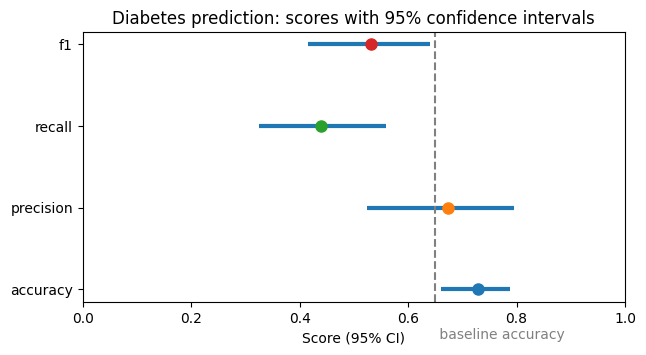

In [8]:
# 각 지표의 점수(점)와 95% 신뢰구간(가로 선)을 그래프로 그리기
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, row in results.iterrows():
    ax.hlines(i, row["하한"], row["상한"], linewidth=3)
    ax.plot(row["점수"], i, "o", markersize=8)

# 기준 모델 정확도를 세로 점선으로 표시
ax.axvline(base_acc, linestyle="--", color="gray")
ax.text(base_acc, -0.6, " baseline accuracy", color="gray")

ax.set_yticks(range(len(results)))
ax.set_yticklabels(results["지표"])
ax.set_xlim(0, 1)
ax.set_xlabel("Score (95% CI)")
ax.set_title("Diabetes prediction: scores with 95% confidence intervals")
plt.show()